In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from scipy.stats import norm

from model import *
from data import generate_gmm_data, generate_uos_data, generate_random_data
from train_utils import train

from plot import *
from utils import *


In [2]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(device)

cuda:0


In [3]:
relu = lambda X: np.maximum(X, 0)
d_relu = lambda X: np.maximum(np.sign(X), 0)

elu = lambda X, alpha=1.0: ( alpha * (np.exp(X) - 1) ) * (X <= 0) + (X * (X > 0))
d_elu = lambda X, alpha=1.0: ( alpha * np.exp(X) ) * (X <= 0) + (X > 0)

gelu = lambda X: X * norm.cdf(X)
d_gelu = lambda X: norm.cdf(X) + X * norm.pdf(X)

sigmoid = lambda X: 1 / (1 + np.exp(-X))
d_sigmoid = lambda X: sigmoid(X) * (1 - sigmoid(X))

silu = lambda X: X * sigmoid(X)
d_silu = lambda X: sigmoid(X) + X * d_sigmoid(X)

leaky_relu = lambda X, slope=0.01: slope * np.minimum(X, 0) + np.maximum(X, 0)
d_leaky_relu = lambda X, slope=0.01: slope * (X <= 0) + (X > 0).astype(float)

identity = lambda X: X
d_identity = lambda X: np.ones(X.shape)

abs_ = lambda X: np.abs(X)
d_abs_ = lambda X: -1 * (X <= 0) + (X > 0)

softplus = lambda X: np.log(1 + np.exp(X))
d_softplus = lambda X: sigmoid(X)

smooth_abs = lambda X, beta = 10: (2 / beta) * softplus(X) - X - ( (2 / beta) * np.log(2) )
d_smooth_abs = lambda X, beta = 10: (2 / beta) * d_softplus(X) - 1

custom_activations_map = {'ReLU': [relu, d_relu],
               'ELU': [elu, d_elu],
               'GELU': [gelu, d_gelu],
               'SiLU': [silu, d_silu],
               'Leaky-ReLU': [leaky_relu, d_leaky_relu],
               'Abs': [abs_, d_abs_],
               'SmoothAbs': [smooth_abs, d_smooth_abs],
               'Identity': [identity, d_identity]}

# Model Training

In [4]:
reduction = 'sum'
loss_map = {
    'ce_loss': nn.CrossEntropyLoss(reduction=reduction),
    'mse_loss': nn.MSELoss(reduction=reduction)
}

data_type_map = {
    'gmm': 'GMM', 
    'uos': 'UoS',
    'random': 'Random'
}

In [37]:
# Data setup
d = 32 # Ambient dim
h_d = d
p = d # Intrinsic dim 
K = 2 # Number of classes
N_k = 500
N = N_k * K
nu = 1e-1

r = np.minimum(K, p)
sr = 4

# Model setup
L = 3
act_fn_str = 'GELU'
act, d_act = custom_activations_map[act_fn_str]
residual = False
batchnorm = False
init_method = 'orthogonal'
init_scale = 1e-1

whiten_ = True
normalize_ = False

# Training setup
epochs = 100
lr = 3e-2
freq = 1
#loss_fn = 'ce_loss'
loss_fn = 'mse_loss'

data_type = 'random'

# Generate train samples
if data_type == 'gmm':
    train_set, train_loader = generate_gmm_data(d, K, N_k, nu=nu, whiten_=whiten_, normalize_=normalize_)
    val_set, val_loader = generate_gmm_data(d, K, N_k, nu=nu, whiten_=whiten_, normalize_=normalize_)
elif data_type == 'uos':
    train_set, train_loader = generate_uos_data(d, K, N_k, subspace_rank=sr, nu=nu, whiten_=whiten_, normalize_=normalize_)
    val_set, val_loader = generate_uos_data(d, K, N_k, subspace_rank=sr, nu=nu, whiten_=whiten_, normalize_=normalize_)
elif data_type == 'random':
    train_set, train_loader = generate_random_data(d, K, N_k, whiten_=whiten_, normalize_=normalize_)
    val_set, val_loader = generate_random_data(d, K, N_k, whiten_=whiten_, normalize_=normalize_)

X = train_set.samples.T
Y = train_set.targets.T


In [39]:
# Train model
model = MLP(L, d, h_d, K, act_fn_str, residual=residual, batchnorm=batchnorm, init_method=init_method, init_scale=init_scale)
model = model.to(device)

# Training
criterion = loss_map[loss_fn]
optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0, weight_decay=0)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs, eta_min=0)
results = train(model, 
                criterion, 
                optimizer, 
                train_loader, 
                val_loader, 
                epochs, 
                device,
                scheduler=scheduler, 
                return_weights=True,
                return_grads=True,
                return_outs=True)


weights = results['all_weights']
grads = results['all_grads']
outs = results['all_outs']

outs_dln = []
for W_t in results['all_weights']:
    out_t = X.copy()
    for Wl_t in W_t:
        out_t = Wl_t @ out_t
        
    outs_dln.append(out_t)

# Calculate E(0)
E_0 = outs[0].T - Y

out_diffs = [np.linalg.norm(outs[t].T - outs_dln[t]) for t in range(epochs)]

Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/100 [00:00<?, ?it/s]2025-08-13 17:52:08,859 - INFO - Finish Epoch 1
2025-08-13 17:52:08,860 - INFO - Train loss: 999.998046875, train accuracy: 54.7
2025-08-13 17:52:08,867 - INFO - Val loss: 999.9993286132812, val accuracy: 54.8
2025-08-13 17:52:08,874 - INFO - Finish Epoch 2
2025-08-13 17:52:08,875 - INFO - Train loss: 999.9971923828125, train accuracy: 57.9
2025-08-13 17:52:08,882 - INFO - Val loss: 999.999267578125, val accuracy: 55.2
2025-08-13 17:52:08,890 - INFO - Finish Epoch 3
2025-08-13 17:52:08,891 - INFO - Train loss: 999.996337890625, train accuracy: 60.6
2025-08-13 17:52:08,898 - INFO - Val loss: 999.9991455078125, val accuracy: 55.5
2025-08-13 17:52:08,905 - INFO - Finish Epoch 4
2025-08-13 17:52:08,906 - INFO - Train loss: 999.9954833984375, train accuracy: 63.2
2025-08-13 17:52:08,913 - INFO - Val loss: 999.9990844726562, val accuracy: 55.4
2025-08-13 17:52:08,921 - INFO - Finish Epoch 5
2025-08-13 17:52:08,922 - INFO - Train loss: 999.9945678710938,

2025-08-13 17:52:09,562 - INFO - Train loss: 999.4473266601562, train accuracy: 97.9
2025-08-13 17:52:09,569 - INFO - Val loss: 999.9328002929688, val accuracy: 53.7
2025-08-13 17:52:09,576 - INFO - Finish Epoch 39
2025-08-13 17:52:09,578 - INFO - Train loss: 999.3115234375, train accuracy: 97.9
2025-08-13 17:52:09,584 - INFO - Val loss: 999.9161987304688, val accuracy: 53.8
2025-08-13 17:52:09,592 - INFO - Finish Epoch 40
2025-08-13 17:52:09,593 - INFO - Train loss: 999.1324462890625, train accuracy: 98.4
2025-08-13 17:52:09,599 - INFO - Val loss: 999.8941650390625, val accuracy: 54.0
2025-08-13 17:52:09,607 - INFO - Finish Epoch 41
2025-08-13 17:52:09,608 - INFO - Train loss: 998.8929443359375, train accuracy: 98.8
2025-08-13 17:52:09,615 - INFO - Val loss: 999.8646240234375, val accuracy: 54.0
2025-08-13 17:52:09,622 - INFO - Finish Epoch 42
2025-08-13 17:52:09,623 - INFO - Train loss: 998.5671997070312, train accuracy: 99.1
2025-08-13 17:52:09,630 - INFO - Val loss: 999.82415771484

2025-08-13 17:52:10,177 - INFO - Val loss: 1284.329833984375, val accuracy: 53.9
 75%|███████▌  | 75/100 [00:01<00:00, 60.42it/s]2025-08-13 17:52:10,185 - INFO - Finish Epoch 76
2025-08-13 17:52:10,187 - INFO - Train loss: 610.6412353515625, train accuracy: 99.2
2025-08-13 17:52:10,193 - INFO - Val loss: 1282.647216796875, val accuracy: 53.9
2025-08-13 17:52:10,200 - INFO - Finish Epoch 77
2025-08-13 17:52:10,202 - INFO - Train loss: 607.6231079101562, train accuracy: 99.2
2025-08-13 17:52:10,208 - INFO - Val loss: 1280.8193359375, val accuracy: 53.9
2025-08-13 17:52:10,215 - INFO - Finish Epoch 78
2025-08-13 17:52:10,217 - INFO - Train loss: 604.5197143554688, train accuracy: 99.2
2025-08-13 17:52:10,223 - INFO - Val loss: 1278.861083984375, val accuracy: 53.9
2025-08-13 17:52:10,230 - INFO - Finish Epoch 79
2025-08-13 17:52:10,232 - INFO - Train loss: 601.3547973632812, train accuracy: 99.2
2025-08-13 17:52:10,238 - INFO - Val loss: 1276.79296875, val accuracy: 53.9
2025-08-13 17:52:

In [ ]:
print(np.linalg.svd(X, compute_uv=False))

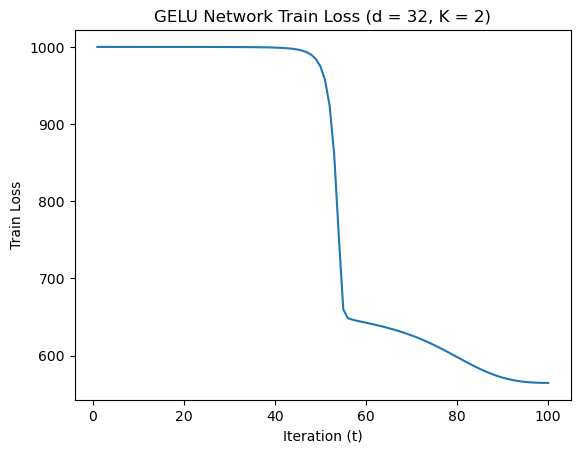

In [40]:
import os

savefig = False
save_dir = loss_fn + '_' + act_fn_str + '_activation_' + init_method + '_init_scale_' + str(init_scale) + '_d_' + str(d) + '_p_' + str(p) + '_K_' + str(K)
if whiten_:
    save_path = os.path.join('./figs/whitened_data', save_dir)
elif normalize_ and not whiten_:
    save_path = os.path.join('./figs/normalized_data', save_dir)
else:
    save_path = os.path.join('./figs/raw_data', save_dir)

if savefig and not os.path.exists(save_path):
    os.makedirs(save_path)


train_losses = np.array(results['train_losses'])
save_fname = os.path.join(save_path, 'train_loss.pdf')
plot_train_losses(train_losses, act_fn_str, d, p, K, save_fname, savefig)

# Weight update subspaces

K =  2
r = 1


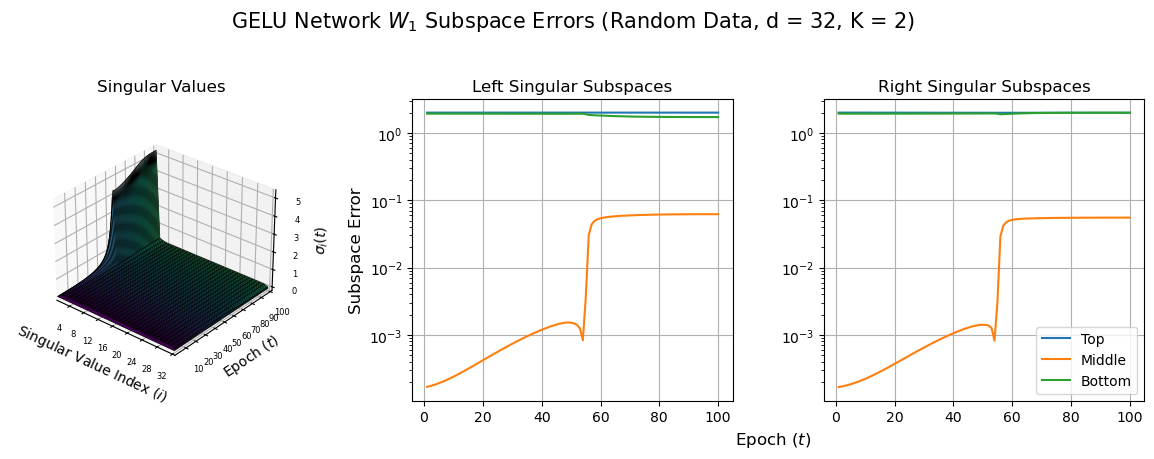

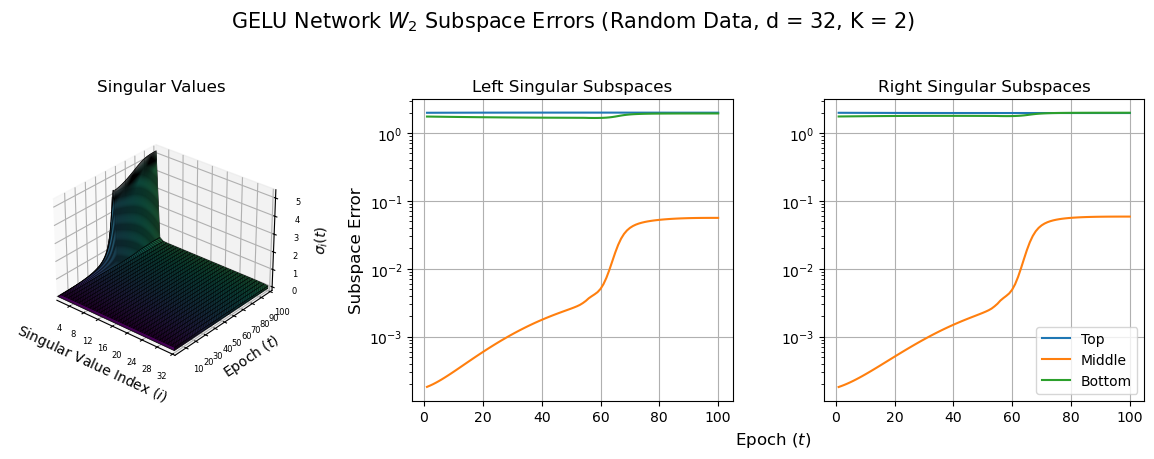



K =  2
r = 2


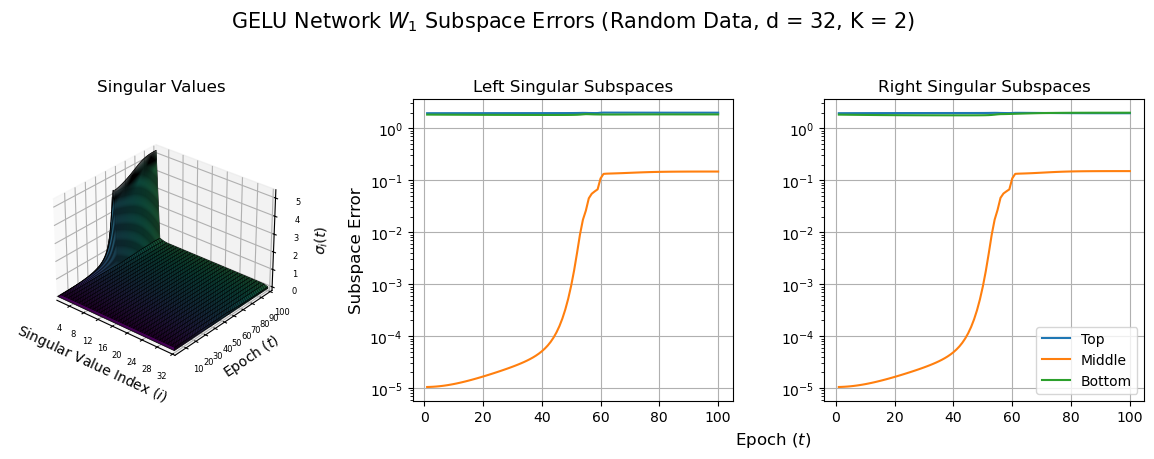

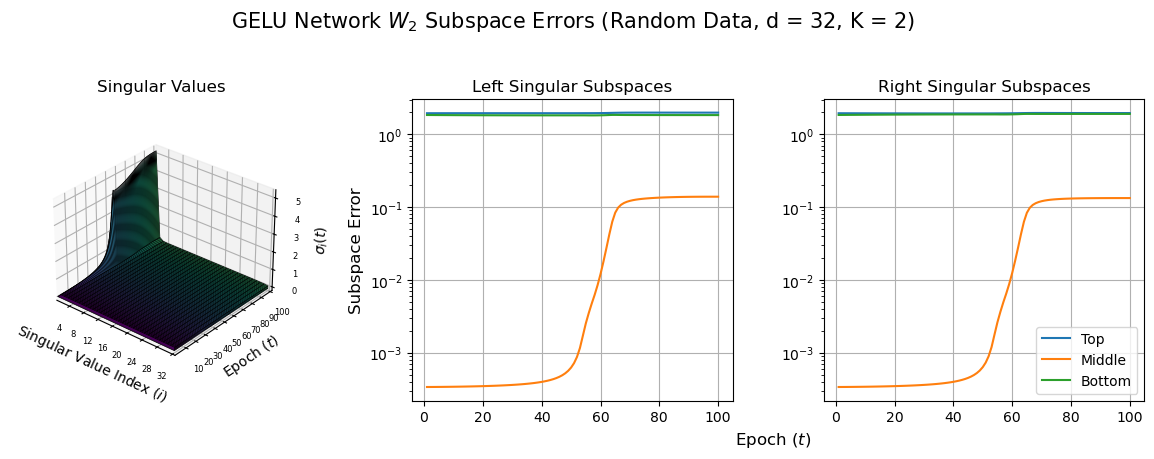



K =  2
r = 3


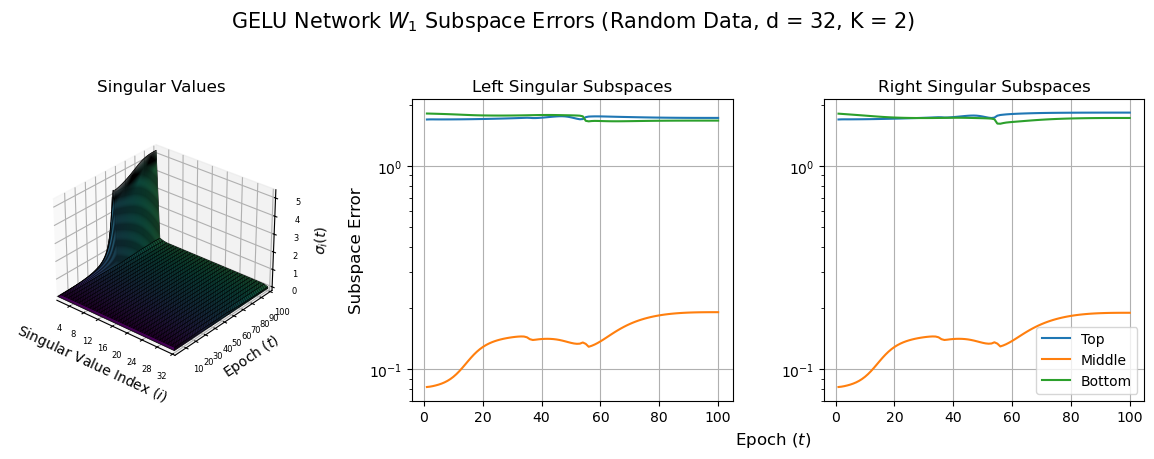

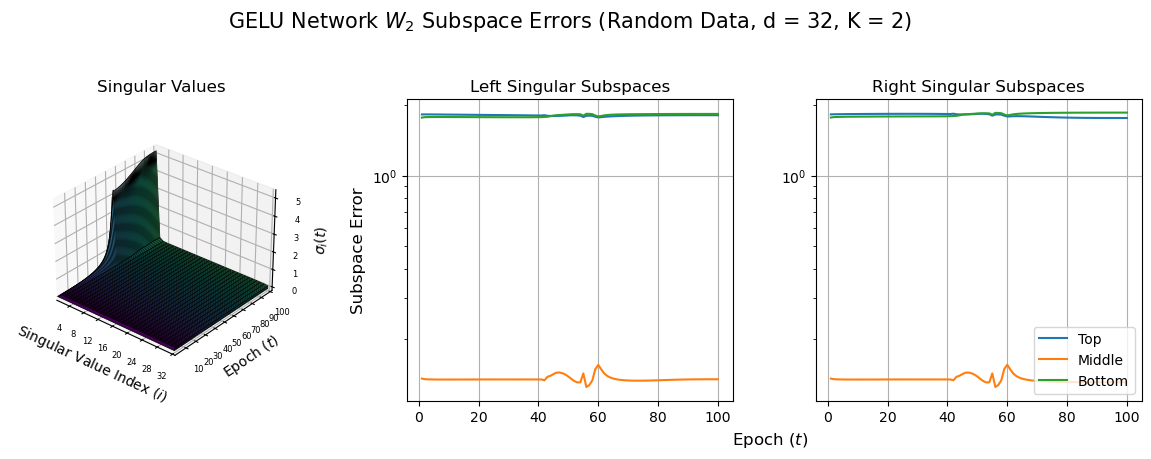



K =  2
r = 4


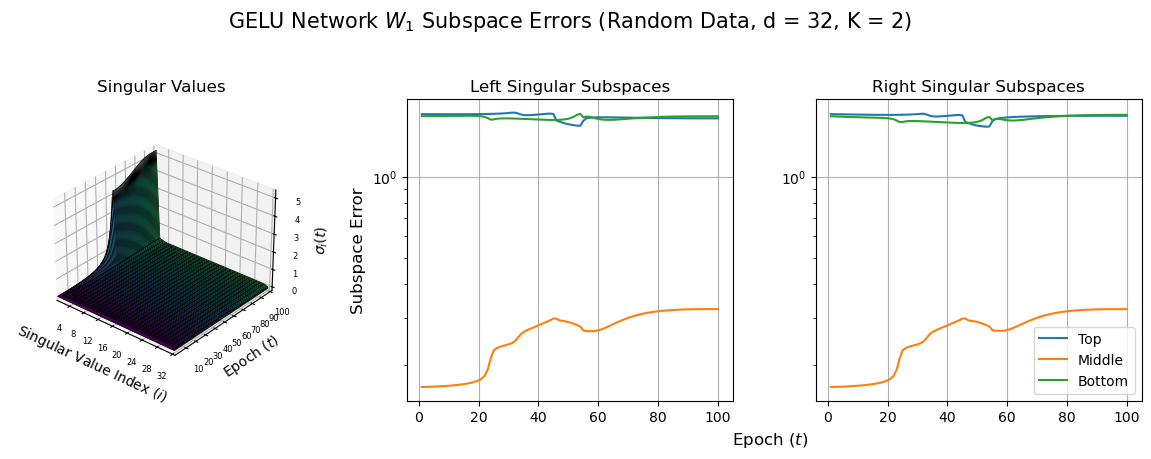

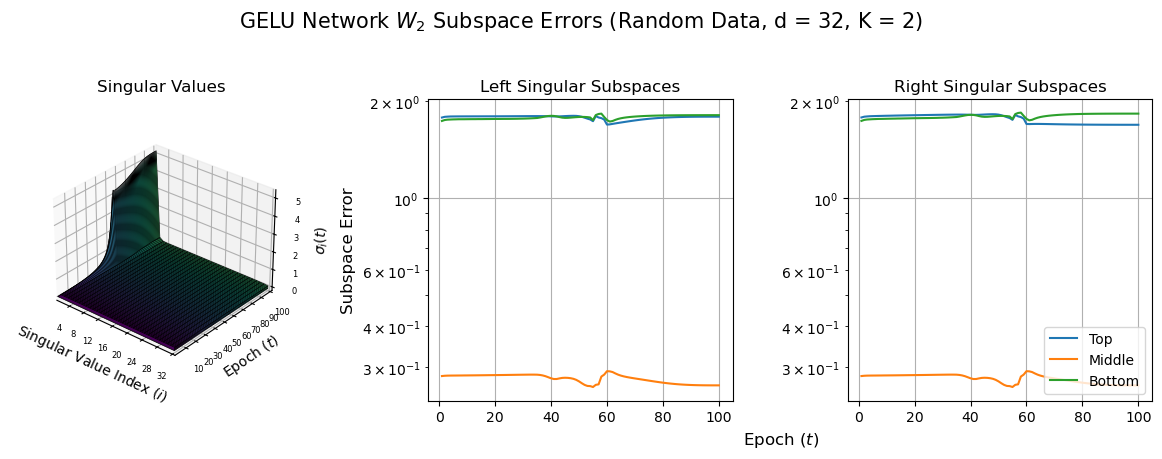

In [41]:
savefig = False
net_dir = act_fn_str + '_network_L_' + str(L) + '_' + init_method + '_init_scale_' + str(init_scale) 
data_dir = data_type + '_synthetic_data_d_' + str(d) + '_K_' + str(K) + '_N_' + str(N)
if whiten_:
    data_dir = 'whitened_' + data_dir
elif normalize_ and not whiten_:
    save_path = 'normalized_' + data_dir
else:
    save_path = 'raw_' + data_dir

save_path = os.path.join('./figs', data_dir, net_dir)
if savefig and not os.path.exists(save_path):
    os.makedirs(save_path)
    
subspace_type = 1

all_rs = np.arange(1, 2*r + 1)

for r_ in all_rs:
    print("K = ", K)
    print("r =", r_)
    result = save_weight_svd_errors(weights, grads, E_0, X, r_, init_scale, subspace_type)

    plot_weight_svd_errors(result, act_fn_str, d, p, K, save_path, subspace_type, data_type.capitalize(), savefig)
    
    print("\n")

In [ ]:
print(result['svals'][0][0])
print(result['svals'][-1][0])

In [ ]:
# result = save_weight_svd_angles(weights, grads, r, init_scale)
# plot_weight_svd_angles(result, act_fn, d, p, K, save_path, savefig)

# Gradient singular values

In [ ]:
idx = -1
grads_idx = grads[idx]

for (l, G_l) in enumerate(grads_idx[:-1]):
    s = svd_(G_l, compute_uv=False)
    plt.figure()
    plt.scatter(np.arange(len(s)) + 1, s)
    plt.title(r'$G_' + str(l + 1) + r'(' + str(idx) + r')$ Singular Values (' + act_fn_str + ', ' + data_type + ' Whitened Data)', fontsize=12 )
    plt.xlabel('SV Index', fontsize=12)
    plt.ylabel('Singular Value', fontsize=12)
    plt.show()
    plt.close()



# Gradient - subspace basis products

In [ ]:
W1_0 = weights[0][0]
W2_0 = weights[0][1]
G1_0 = grads[0][0]

E_0 = (W2_0 @ act(W1_0 @ X) - Y)

U_null, V_null = small_update_subspace(W1_0, G1_0, K, init_scale)
U_null2, V_null2 = small_update_subspace_2(weights[0], E_0, X, K, init_scale)

print(subspace_error(V_null, V_null2))
print(subspace_error(U_null, U_null2))


X_V_prod_norms = []
G_V_prod_norms = []

W1_V_prod_norms = []
D_W1_V_prod_norms = []
G_W1_V_prod_norms = []

G_norms = []
G_W1_norms = []

D_U_prod_norms = []
G_U_prod_norms = []

W2_E_X_norms = []
W2_E_X_V_norms = []


for t in range(epochs):
    G1_t = grads[t][0]
    W1_t = weights[t][0]
    W2_t = weights[t][1]
    Z2_t = W2_t @ act(W1_t @ X)
    E_t = Z2_t - Y
    

    Delta1_1_t = W2_t.T @ E_t
    Delta1_2_t = d_act(W1_t @ X)

    Delta_1_t = Delta1_1_t * Delta1_2_t
    G1_t_an = Delta_1_t @ X.T
    
    
    G1_t_norm = np.linalg.norm(G1_t_an, ord='fro')
    G_W1_t_norm = np.linalg.norm(G1_t_an.T @ W1_t, ord='fro')
    
    G_norms.append(G1_t_norm)
    G_W1_norms.append(G_W1_t_norm)
    
    X_V_prod_norms.append(np.linalg.norm(X.T @ V_null2, ord='fro'))
    G_V_prod_norms.append(np.linalg.norm(G1_t_an @ V_null2, ord='fro'))
    
    W1_V_prod_norms.append(np.linalg.norm(W1_t @ V_null2, ord='fro'))
    D_W1_V_prod_norms.append(np.linalg.norm(Delta_1_t.T @ W1_t @ V_null2, ord='fro'))
    G_W1_V_prod_norms.append(np.linalg.norm(G1_t_an.T @  W1_t @ V_null2))
    
    D_U_prod_norms.append(np.linalg.norm(Delta_1_t.T @ U_null2, ord='fro'))
    G_U_prod_norms.append(np.linalg.norm(G1_t_an.T @ U_null2, ord='fro'))
    
    
    A_t = W2_t.T @ E_t @ X.T
    W2_E_X_norms.append(np.linalg.norm(A_t, ord='fro'))
    W2_E_X_V_norms.append(np.linalg.norm(A_t @ V_null2, ord='fro'))
    
    


plt.figure()
plt.plot(np.arange(epochs) + 1, G_norms, label=r'$G_1(t)$')
plt.plot(np.arange(epochs) + 1, X_V_prod_norms, label=r'$X^\top V$')
plt.plot(np.arange(epochs) + 1, G_V_prod_norms, label=r'$\Delta_1(t) X^\top V$')
plt.title('V Matrix Product Frobenius Norms (' + act_fn_str + ')')
plt.legend()
plt.grid()
plt.show()
plt.close()

plt.figure()
plt.plot(np.arange(epochs) + 1, G_norms, label=r'$G_1(t)$')
plt.plot(np.arange(epochs) + 1, D_U_prod_norms, label=r'$\Delta_1^\top(t) U$')
plt.plot(np.arange(epochs) + 1, G_U_prod_norms, label=r'$X \Delta_1^\top(t) U$')
plt.title('U Matrix Product Frobenius Norms (' + act_fn_str + ')')
plt.legend()
plt.grid()
plt.show()
plt.close()

plt.figure()
plt.plot(np.arange(epochs) + 1, W2_E_X_norms, label=r'$W_2(t)^\top E(t) X$')
plt.plot(np.arange(epochs) + 1, W2_E_X_V_norms, label=r'$W_2(t)^\top E(t) X^\top V$')
plt.legend()
plt.grid()
plt.show()
plt.close()

print(W2_E_X_V_norms[0])


# Perturbation matrix

In [ ]:
phi_neg = lambda x: np.exp(x) - 1

W1_0 = weights_init[0]
W2_0 = weights_init[1]
G1_0 = grads[0][0]

M_bar = (W1_0 @ X) <= 0

Delta_2_0 = (W2_0 @ elu(W1_0 @ X) - Y)
W2_D2 = W2_0.T @ Delta_2_0
W2_Gamma = W2_D2 @ X.T

P0_no_mask = W2_D2 * phi_neg(W1_0 @ X) 
P0 = P0_no_mask * M_bar


P0_tilde_no_mask = P0_no_mask @ X.T
P0_tilde = P0 @ X.T


#U_null, V_null = small_update_subspace(W1_0, G1_0, K, init_scale)
U_null, V_null = small_update_subspace_2(weights_init, Delta_2_0, X, K, init_scale)

S1 = svd_(G1_0)[-1][:, K:]
S2 = svd_(G1_0.T @ W1_0)[-1][:, K:]


S1_tilde = svd_(W2_Gamma)[-1][:, K:]
S2_tilde = svd_(W2_Gamma.T @ W1_0)[-1][:, K:]


# print(subspace_error(S1, S1_tilde))
# print(subspace_error(S2, S2_tilde))
# print(subspace_error(V_null, V_null2))
# print(np.linalg.norm(G1_0 @ V_null,ord='fro'))
# print(np.linalg.norm(G1_0 @ V_null2,ord='fro'))


P0_tilde_V = P0_tilde @ V_null
P0_tilde_no_mask_V = P0_tilde_no_mask @ V_null
P0_tilde_U = P0_tilde.T @ U_null
P0_tilde_no_mask_U = P0_tilde_no_mask.T @ U_null


phi_neg_norms = [np.linalg.norm(phi_neg(W1_0 @ X), ord='fro')]
G1_norms = [np.linalg.norm(G1_0, ord='fro')]
W2_D2_norms = [np.linalg.norm(W2_D2, ord='fro')]
W2_Gamma_norms = [np.linalg.norm(W2_Gamma, ord='fro')]
W2_Gamma_V_norms = [np.linalg.norm(W2_Gamma @ V_null, ord='fro')]
W2_Gamma_U_norms = [np.linalg.norm(W2_Gamma.T @ U_null, ord='fro')]

P_norms = [np.linalg.norm(P0, ord='fro')]
P_no_mask_norms = [np.linalg.norm(P0_no_mask, ord='fro')]

P_tilde_norms = [np.linalg.norm(P0_tilde, ord='fro')]
P_tilde_no_mask_norms = [np.linalg.norm(P0_tilde_no_mask, ord='fro')]

P_tilde_V_norms = [np.linalg.norm(P0_tilde_V, ord='fro')]
P_tilde_no_mask_V_norms = [np.linalg.norm(P0_tilde_no_mask_V, ord='fro')]

P_tilde_U_norms = [np.linalg.norm(P0_tilde_U, ord='fro')]
P_tilde_no_mask_U_norms = [np.linalg.norm(P0_tilde_no_mask_U, ord='fro')]


for t in range(1, epochs):
    print('===== EPOCH ' + str(t) + ' =====')
    G1_t = grads[t][0]
    W1_t = weights[t][0]
    W2_t = weights[t][1]
    
    G1_norms.append(np.linalg.norm(G1_t, ord='fro'))
    phi_neg_norms.append(np.linalg.norm(phi_neg(W1_t @ X), ord='fro'))
    
    Delta_2_t = (W2_t @ elu(W1_t @ X) - Y)
    W2_D2 = W2_t.T @ Delta_2_t
    W2_D2_norms.append(np.linalg.norm(W2_D2, ord='fro'))
    
    W2_Gamma = W2_D2 @ X.T
    W2_Gamma_norms.append(np.linalg.norm(W2_Gamma, ord='fro'))
    W2_Gamma_V_norms.append(np.linalg.norm(W2_Gamma @ V_null, ord='fro'))
    W2_Gamma_U_norms.append(np.linalg.norm(W2_Gamma.T @ U_null, ord='fro'))
    
    
    Pt_no_mask = W2_D2 * phi_neg(W1_t @ X)
    Pt = Pt_no_mask * M_bar
    
    P_norms.append(np.linalg.norm(Pt, ord='fro'))
    P_no_mask_norms.append(np.linalg.norm(Pt_no_mask, ord='fro'))
    
    Pt_tilde = Pt @ X.T
    Pt_tilde_no_mask = Pt_no_mask @ X.T
    P_tilde_norms.append(np.linalg.norm(Pt_tilde, ord='fro'))
    P_tilde_no_mask_norms.append(np.linalg.norm(Pt_tilde_no_mask, ord='fro'))
    
    
    Pt_tilde_V = Pt_tilde @ V_null
    Pt_tilde_U = Pt_tilde.T @ U_null
    P_tilde_V_norms.append(np.linalg.norm(Pt_tilde_V, ord='fro'))
    P_tilde_U_norms.append(np.linalg.norm(Pt_tilde_U, ord='fro'))
    
    Pt_tilde_no_mask_V = Pt_tilde_no_mask @ V_null
    Pt_tilde_no_mask_U = Pt_tilde_no_mask.T @ U_null
    P_tilde_no_mask_V_norms.append(np.linalg.norm(Pt_tilde_no_mask_V, ord='fro'))
    P_tilde_no_mask_U_norms.append(np.linalg.norm(Pt_tilde_no_mask_U, ord='fro'))
    
    
    #Ut_null, Vt_null = small_update_subspace_2(weights[t], Delta_2_t, X, K, init_scale)
    
#     print(np.linalg.norm(W2_Gamma @ V_null, ord='fro'))
#     print(np.linalg.norm(W2_Gamma, ord='fro'))

    print("W_2(t).T Gamma(0) svals = ", np.linalg.svd(W2_Gamma, compute_uv=False))
    print("P(t) X.T svals = ", np.linalg.svd(Pt_tilde, compute_uv=False))
    print("W_2(t)^.T Gamma(t) + P(t)X.T svals = ", np.linalg.svd(W2_Gamma + Pt_tilde, compute_uv=False))


    
#     Pt_tilde_svals = np.linalg.svd(Pt_tilde, compute_uv=False)
#     Pt_tilde_no_mask_svals = np.linalg.svd(Pt_tilde_no_mask, compute_uv=False)
#     W2_Gamma_svals = np.linalg.svd(W2_Gamma, compute_uv=False)

#     plt.figure()
#     plt.scatter(np.arange(len(Pt_tilde_svals)), Pt_tilde_svals, label=r'$P(t)$ with mask')
#     plt.scatter(np.arange(len(Pt_tilde_no_mask_svals)), Pt_tilde_no_mask_svals, label=r'$P(t)$ without mask')
#     plt.scatter(np.arange(len(W2_Gamma_svals)), W2_Gamma_svals, label=r'$W_2^\top(t) \Gamma(t)$')
#     plt.legend()
#     plt.title('Epoch ' + str(t))
#     #plt.yscale('log')
#     plt.show()
#     plt.close()
    
    

plt.figure()
plt.plot(np.arange(epochs), P_norms, label=r'$\|P(t)\|_F$ with mask')
plt.plot(np.arange(epochs), P_tilde_norms, label=r'$\|P(t) X^\top\|_F$ with mask')
plt.plot(np.arange(epochs), P_tilde_V_norms, label=r'$\|P(t) X^\top V\|_F$ with mask')
plt.plot(np.arange(epochs), P_tilde_U_norms, label=r'$\|X P^\top(t) U\|_F$ with mask')

plt.plot(np.arange(epochs), P_no_mask_norms, label=r'$\|P(t)\|_F$ without mask')
plt.plot(np.arange(epochs), P_tilde_no_mask_norms, label=r'$\|P(t) X^\top\|_F$ without mask')
plt.plot(np.arange(epochs), P_tilde_no_mask_V_norms, label=r'$\|P(t) X^\top V\|_F$ without mask')
plt.plot(np.arange(epochs), P_tilde_no_mask_U_norms, label=r'$\|X P^\top(t) U\|_F$ without mask')
#plt.plot(np.arange(epochs), G1_norms, label=r'$\|G_1(t)\|_F$')
#plt.plot(np.arange(epochs), W2_Gamma_norms, label=r'$\|W_2(t) \Delta_2(t)\|_F$')
plt.legend(ncol=2)
plt.title('Permutation Matrix Product Norms')
plt.grid('on')
plt.ylim([0,6])
plt.show()
plt.close()


plt.figure()
#plt.plot(np.arange(epochs), P_no_mask_norms, label=r'$\|P(t)\|_F$')
plt.plot(np.arange(epochs), P_tilde_no_mask_norms, label=r'$\|P(t) X^\top\|_F$')
plt.plot(np.arange(epochs), P_tilde_no_mask_V_norms, label=r'$\|P(t) X^\top V\|_F$')
plt.plot(np.arange(epochs), P_tilde_no_mask_U_norms, label=r'$\|X^\top P(t) U\|_F$')
plt.plot(np.arange(epochs), G1_norms, label=r'$\|G_1(t)\|_F$')
plt.plot(np.arange(epochs), W2_Gamma_norms, label=r'$\|W_2(t) \Gamma_2(t)\|_F$')
plt.legend(ncol=1)
plt.title('Perturbation (without mask) and gradient norms')
plt.show()
plt.close()

plt.figure()
plt.plot(np.arange(epochs), G1_norms, label=r'$\|G_1(t)\|_F$')
plt.plot(np.arange(epochs), W2_Gamma_norms, label=r'$\|W_2^\top(t) \Gamma_2(t)\|_F$')
plt.plot(np.arange(epochs), P_norms, label=r'$\|P(t)\|_F$ with mask')
plt.plot(np.arange(epochs), P_no_mask_norms, label=r'$\|P(t)\|_F$ without mask')
plt.plot(np.arange(epochs), W2_D2_norms, label=r'$\|W_2^\top(t) \Delta_2(t)\|_F$')
plt.plot(np.arange(epochs), P_tilde_norms, label=r'$\|P(t) X^\top\|_F$ with mask')
plt.plot(np.arange(epochs), P_tilde_no_mask_norms, label=r'$\|P(t) X^\top\|_F$ without mask')
plt.plot(np.arange(epochs), phi_neg_norms, label=r'$\phi_{-}(W_1(t) X)$')
#plt.plot(np.arange(epochs), W2_Gamma_V_norms, label=r'$\|W_2^\top(t) \Gamma_2(t) V\|_F$')
#plt.plot(np.arange(epochs), W2_Gamma_U_norms, label=r'$\|\Gamma_2^\top(t) W_2(t) U\|_F$')
plt.legend(ncol=1, loc='upper right')
plt.grid('on')
plt.title('Gradient and Perturbation Norms')
plt.show()
plt.close()

plt.figure()

plt.show()


# Nullspace evolution

In [ ]:
W1_0 = weights[0][0]
W2_0 = weights[0][1]
G1_0 = grads[0][0]

E_0 = (W2_0 @ act(W1_0 @ X) - Y)

U_null, V_null = small_update_subspace_2(weights[0], E_0, X, K, init_scale)

G_norms = []

W2_Gamma_V_norms = []
Gamma_W21_V_norms = []

Vt_V_errors = []
for t in range(epochs):
    G_t = grads[t][0]
    W1_t = weights[t][0]
    W2_t = weights[t][1]
    Z2_t = W2_t @ act(W1_t @ X)
    E_t = Z2_t - Y
    
    G_norms.append(np.linalg.norm(G_t, ord='fro'))
    
    Gamma_t = E_t @ X.T
    
    W2_Gamma_t = W2_t.T @ Gamma_t
    Gamma_W21_t = Gamma_t.T @ W2_t @ W1_t
    
    W2_Gamma_V_norm = np.linalg.norm(W2_Gamma_t @ V_null, ord='fro')
    Gamma_W21_V_norm = np.linalg.norm(Gamma_W21_t @ V_null, ord='fro')
    
    W2_Gamma_V_norms.append(W2_Gamma_V_norm)
    Gamma_W21_V_norms.append(Gamma_W21_V_norm)
    
    _, Vt_null = small_update_subspace_2(weights[t], E_t, X, K, init_scale)
    Vt_V_errors.append(subspace_error(Vt_null, V_null))
    
    
    

plt.figure()
#plt.plot(np.arange(epochs) + 1, G_norms, label=r'$\| G(t) \|_F$')
plt.plot(np.arange(epochs) + 1, W2_Gamma_V_norms, label=r'$\| W_2^\top(t) \Gamma(t) V \|_F$')
plt.plot(np.arange(epochs) + 1, Gamma_W21_V_norms, label=r'$\| \Gamma^\top(t) W_{2:1}(t) V \|_F$')
plt.plot(np.arange(epochs) + 1, Vt_V_errors, label=r'$V$ and $V(t)$ subspace errors')
plt.title('Nullspace Evolutions (' + act_fn_str + ')')
plt.yscale('linear')
plt.legend()
plt.grid()
plt.show()
plt.close()



